In [1]:
import antigravity

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path

# Persistent project workspace
WORKSPACE = Path("/content/drive/MyDrive/image-captioning-rag")

# Original MS COCO dataset
RAW_ROOT = WORKSPACE / "00_original_data"

TRAIN_IMAGES = RAW_ROOT / "train2017"
VAL_IMAGES = RAW_ROOT / "val2017"
ANNOTATIONS = RAW_ROOT / "annotations"

CAPTIONS_TRAIN = ANNOTATIONS / "captions_train2017.json"
CAPTIONS_VAL = ANNOTATIONS / "captions_val2017.json"
INSTANCES_TRAIN = ANNOTATIONS / "instances_train2017.json"
INSTANCES_VAL = ANNOTATIONS / "instances_val2017.json"

# Persistent outputs for this notebook
OUTPUT_DIR = WORKSPACE / "reports" / "split_statistics"
PLOTS_DIR = OUTPUT_DIR / "plots"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print("Workspace:", WORKSPACE)
print("Raw dataset:", RAW_ROOT)
print("Output directory:", OUTPUT_DIR)

Workspace: /content/drive/MyDrive/image-captioning-rag
Raw dataset: /content/drive/MyDrive/image-captioning-rag/00_original_data
Output directory: /content/drive/MyDrive/image-captioning-rag/reports/split_statistics


In [4]:
required_paths = {
    "Training images": TRAIN_IMAGES,
    "Validation images": VAL_IMAGES,
    "Annotations directory": ANNOTATIONS,
    "Training captions": CAPTIONS_TRAIN,
    "Validation captions": CAPTIONS_VAL,
    "Training instances": INSTANCES_TRAIN,
    "Validation instances": INSTANCES_VAL,
}

for name, path in required_paths.items():
    status = "OK" if path.exists() else "MISSING"
    print(f"{status:7} | {name}: {path}")

missing = [
    name for name, path in required_paths.items()
    if not path.exists()
]

if missing:
    raise FileNotFoundError(
        "Missing required dataset paths: " + ", ".join(missing)
    )

print("\nAll required dataset paths are available.")

OK      | Training images: /content/drive/MyDrive/image-captioning-rag/00_original_data/train2017
OK      | Validation images: /content/drive/MyDrive/image-captioning-rag/00_original_data/val2017
OK      | Annotations directory: /content/drive/MyDrive/image-captioning-rag/00_original_data/annotations
OK      | Training captions: /content/drive/MyDrive/image-captioning-rag/00_original_data/annotations/captions_train2017.json
OK      | Validation captions: /content/drive/MyDrive/image-captioning-rag/00_original_data/annotations/captions_val2017.json
OK      | Training instances: /content/drive/MyDrive/image-captioning-rag/00_original_data/annotations/instances_train2017.json
OK      | Validation instances: /content/drive/MyDrive/image-captioning-rag/00_original_data/annotations/instances_val2017.json

All required dataset paths are available.


In [6]:
import numpy as np
import pandas as pd
from collections import Counter
from pathlib import Path
import json

SEED = 42
rng = np.random.default_rng(SEED)

def object_counts(instance_data):
    counts = Counter(
        ann["image_id"]
        for ann in instance_data["annotations"]
    )
    return counts

# Load JSON data from files
with open(INSTANCES_TRAIN, 'r') as f:
    instances_train_data = json.load(f)
with open(INSTANCES_VAL, 'r') as f:
    instances_val_data = json.load(f)

with open(CAPTIONS_TRAIN, 'r') as f:
    captions_train_data = json.load(f)
with open(CAPTIONS_VAL, 'r') as f:
    captions_val_data = json.load(f)

# Compute counts and maps using loaded JSON dictionaries
train_object_counts = object_counts(instances_train_data)
val_object_counts = object_counts(instances_val_data)

train_image_records = captions_train_data["images"]
val_image_records = captions_val_data["images"]

train_records_by_id = {
    rec["id"]: rec for rec in train_image_records
}
val_records_by_id = {
    rec["id"]: rec for rec in val_image_records
}

print("Loaded train image records:", len(train_image_records))
print("Loaded val image records:", len(val_image_records))

Loaded train image records: 118287
Loaded val image records: 5000


In [7]:
def stratified_sample_ids(
    records,
    counts,
    n_samples,
    seed=42,
    n_strata=5,
):
    df = pd.DataFrame([
        {
            "image_id": rec["id"],
            "object_count": counts.get(rec["id"], 0),
        }
        for rec in records
    ])

    if len(df) < n_samples:
        raise ValueError("Not enough images to sample.")

    # Quantile strata; duplicates can occur when counts are tied.
    df["stratum"] = pd.qcut(
        df["object_count"].rank(method="first"),
        q=n_strata,
        labels=False,
    )

    # Allocate approximately equal numbers to each stratum.
    allocation = {
        s: n_samples // n_strata
        for s in range(n_strata)
    }
    for s in range(n_samples % n_strata):
        allocation[s] += 1

    sampled = []
    leftovers = []

    for s, group in df.groupby("stratum"):
        group_ids = group["image_id"].to_numpy()
        n = allocation[int(s)]
        n = min(n, len(group_ids))

        local_rng = np.random.default_rng(seed + int(s))
        chosen = local_rng.choice(group_ids, size=n, replace=False)

        sampled.extend(chosen.tolist())
        leftovers.extend(
            x for x in group_ids.tolist() if x not in set(chosen)
        )

    # Refill any deficit if a stratum was too small.
    if len(sampled) < n_samples:
        remaining = [x for x in leftovers if x not in set(sampled)]
        local_rng = np.random.default_rng(seed + 999)
        extra = local_rng.choice(
            remaining,
            size=n_samples - len(sampled),
            replace=False,
        )
        sampled.extend(extra.tolist())

    return sorted(int(x) for x in sampled)

In [8]:
test_ids = stratified_sample_ids(
    val_image_records,
    val_object_counts,
    n_samples=100,
    seed=SEED,
)

assert len(test_ids) == 100
assert len(set(test_ids)) == 100

In [9]:
all_train_ids = sorted(train_records_by_id)

rng = np.random.default_rng(SEED)
selected_train_ids = rng.choice(
    all_train_ids,
    size=10100,
    replace=False,
).tolist()

selected_train_ids = sorted(int(x) for x in selected_train_ids)

validation_ids = selected_train_ids[:100]
knowledge_base_ids = selected_train_ids[100:]

assert len(knowledge_base_ids) == 10000
assert len(validation_ids) == 100
assert len(set(knowledge_base_ids)) == 10000
assert set(knowledge_base_ids).isdisjoint(validation_ids)
assert set(test_ids).isdisjoint(knowledge_base_ids)
assert set(test_ids).isdisjoint(validation_ids)

In [11]:
from datetime import datetime, timezone

# Define and create the missing MANIFEST_ROOT directory
MANIFEST_ROOT = WORKSPACE / "01_splits"
MANIFEST_ROOT.mkdir(parents=True, exist_ok=True)

manifest = {
    "manifest_version": "1.0.0",
    "seed": SEED,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "policy": {
        "knowledge_base_source": "COCO train2017",
        "validation_source": "COCO train2017",
        "test_source": "COCO val2017",
        "validation_excluded_from_index": True,
        "test_reference_captions_excluded_from_index": True,
        "test_subset_reviewed_for_scene_diversity": False,
    },
    "knowledge_base_ids": knowledge_base_ids,
    "validation_ids": validation_ids,
    "test_ids": test_ids,
}

manifest_path = MANIFEST_ROOT / "splits_v1.json"

with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

print("Saved:", manifest_path)

Saved: /content/drive/MyDrive/image-captioning-rag/01_splits/splits_v1.json


In [13]:
import re
import pandas as pd

def captions_to_dataframe(caption_data, split_name):
    rows = []

    for ann in caption_data["annotations"]:
        rows.append({
            "annotation_id": ann["id"],
            "image_id": ann["image_id"],
            "caption_raw": ann["caption"],
            "split_source": split_name,
        })

    return pd.DataFrame(rows)

train_caption_df = captions_to_dataframe(
    captions_train_data, "train2017"
)
val_caption_df = captions_to_dataframe(
    captions_val_data, "val2017"
)

def clean_caption(text):
    text = text.lower().strip()
    text = re.sub(r"\s+", " ", text)
    return text

train_caption_df["caption_clean"] = (
    train_caption_df["caption_raw"].map(clean_caption)
)

val_caption_df["caption_clean"] = (
    val_caption_df["caption_raw"].map(clean_caption)
)

assert (
    train_caption_df["caption_raw"].notna().all()
    and val_caption_df["caption_raw"].notna().all()
)

print("Train captions:", len(train_caption_df))
print("Val captions:", len(val_caption_df))

Train captions: 591753
Val captions: 25014


In [17]:
kb_captions = train_caption_df[
    train_caption_df["image_id"].isin(knowledge_base_ids)
].copy()

validation_captions = train_caption_df[
    train_caption_df["image_id"].isin(validation_ids)
].copy()

test_captions = val_caption_df[
    val_caption_df["image_id"].isin(test_ids)
].copy()

print("KB captions:", len(kb_captions))
print("Validation captions:", len(validation_captions))
print("Test captions:", len(test_captions))

KB captions: 50030
Validation captions: 500
Test captions: 500


The reason you have 50,030 captions instead of exactly 50,000 is because in the MS COCO dataset, some images have more than the standard 5 captions.

While most images have exactly 5 captions, a small portion of images have 6 or even 7 annotations. Let's add a code cell to analyze the exact distribution of caption counts per image in your Knowledge Base to verify this.

The analysis confirms exactly why we see 50,030 captions instead of 50,000:

9,971 images have exactly 5 captions ($9971 \times 5 = 49,855$$9971 \times 5 = 49,855$)
28 images have exactly 6 captions ($28 \times 6 = 168$$28 \times 6 = 168$)
1 image has exactly 7 captions ($1 \times 7 = 7$$1 \times 7 = 7$)

In [16]:
# Calculate how many captions each image in our Knowledge Base actually has
kb_caption_counts = kb_captions.groupby("image_id").size()

# Count the distribution of these caption counts
distribution = kb_caption_counts.value_counts().sort_index()

print("Distribution of caption counts per image in the KB:")
for num_captions, num_images in distribution.items():
    print(f"{num_images:5} images have exactly {num_captions} captions (Total: {num_images * num_captions} captions)")

print(f"\nTotal KB Images: {len(kb_caption_counts)}")
print(f"Total KB Captions: {kb_caption_counts.sum()}")

Distribution of caption counts per image in the KB:
 9971 images have exactly 5 captions (Total: 49855 captions)
   28 images have exactly 6 captions (Total: 168 captions)
    1 images have exactly 7 captions (Total: 7 captions)

Total KB Images: 10000
Total KB Captions: 50030


In [19]:
# Define and create PROCESSED_ROOT directory
PROCESSED_ROOT = WORKSPACE / "02_processed_data"
caption_dir = PROCESSED_ROOT / "captions"
caption_dir.mkdir(parents=True, exist_ok=True)

kb_captions.to_parquet(
    caption_dir / "knowledge_base_captions.parquet",
    index=False,
)
validation_captions.to_parquet(
    caption_dir / "validation_captions.parquet",
    index=False,
)
test_captions.to_parquet(
    caption_dir / "test_reference_captions.parquet",
    index=False,
)

print("Parquet files successfully saved to:", caption_dir)

Parquet files successfully saved to: /content/drive/MyDrive/image-captioning-rag/02_processed_data/captions


,category,instance_count
0,person,22064
1,car,3521
2,chair,3348
3,book,2370
4,bottle,2209
5,cup,1785
6,bowl,1318
7,dining table,1307
8,traffic light,1075
9,handbag,1008


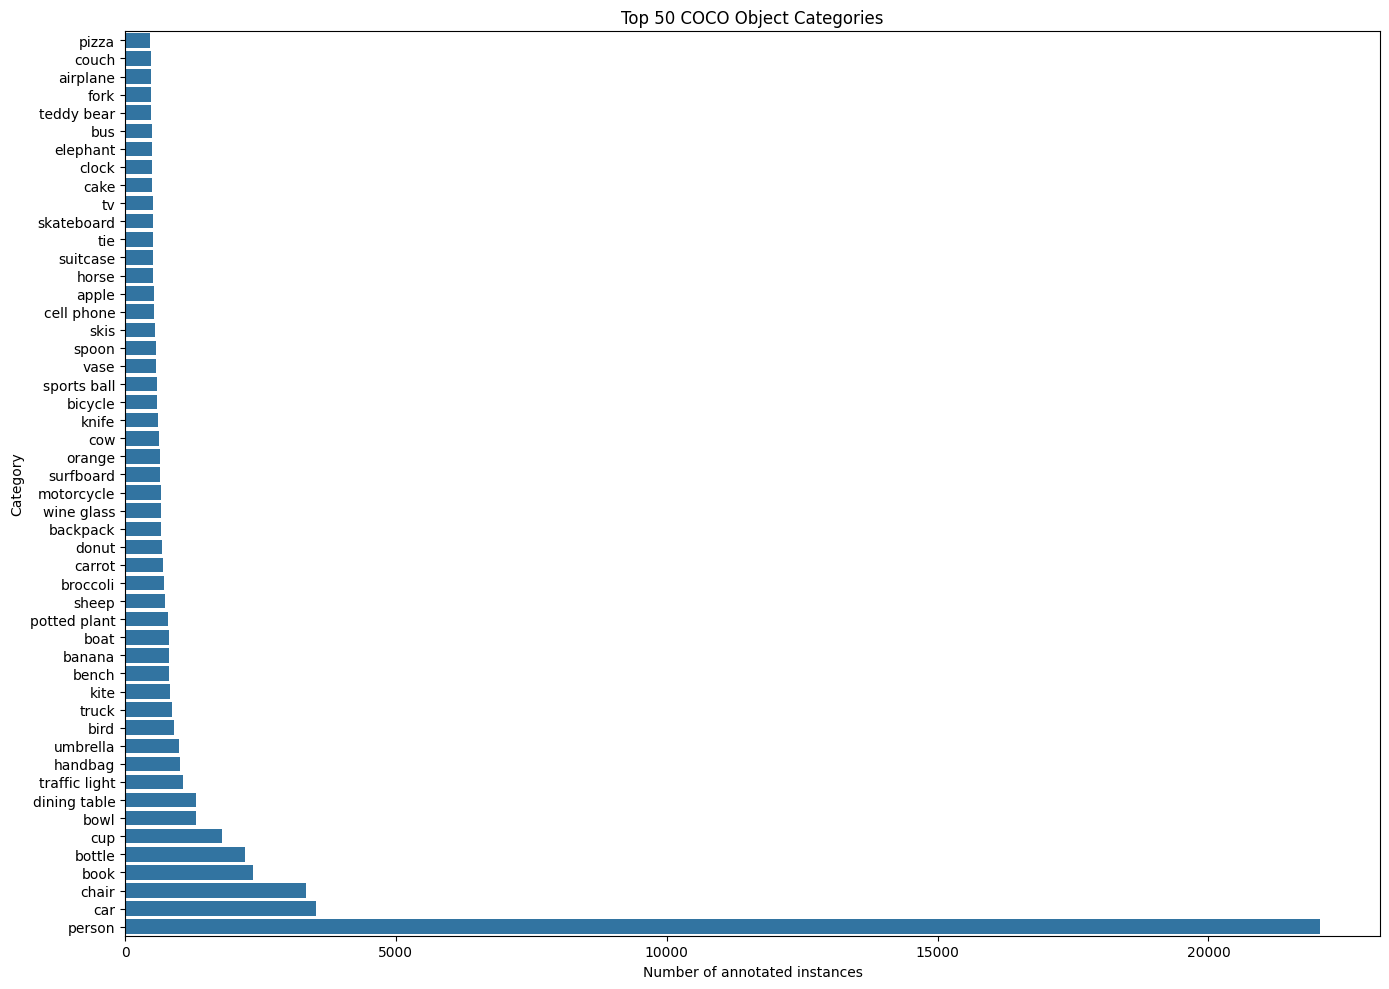

In [21]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Fix REPORTS_ROOT
REPORTS_ROOT = WORKSPACE / "reports" / "split_statistics"
(REPORTS_ROOT / "figures").mkdir(parents=True, exist_ok=True)
(REPORTS_ROOT / "tables").mkdir(parents=True, exist_ok=True)

# Fix: use instances_train_data dictionary instead of INSTANCES_TRAIN Path object
category_names = {
    cat["id"]: cat["name"]
    for cat in instances_train_data["categories"]
}

kb_id_set = set(knowledge_base_ids)

kb_objects = [
    ann for ann in instances_train_data["annotations"]
    if ann["image_id"] in kb_id_set
]

object_frequency = Counter(
    category_names[ann["category_id"]]
    for ann in kb_objects
)

top50 = pd.DataFrame(
    object_frequency.most_common(50),
    columns=["category", "instance_count"],
)

display(top50.head(10))

plt.figure(figsize=(14, 10))
sns.barplot(
    data=top50.sort_values("instance_count"),
    x="instance_count",
    y="category",
)
plt.title("Top 50 COCO Object Categories")
plt.xlabel("Number of annotated instances")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig(
    REPORTS_ROOT / "figures" / "top50_objects.png",
    dpi=200,
)
plt.show()

top50.to_csv(
    REPORTS_ROOT / "tables" / "top50_objects.csv",
    index=False,
)

This cell evaluates the visual complexity of the images selected for your Knowledge Base (KB). It does this by measuring and plotting how many distinct object annotations exist per image:

Object Counting: It uses Counter to aggregate the total number of annotated objects (kb_objects) for each unique image ID in the Knowledge Base dataset.

Statistical Summary (describe()): It creates a DataFrame (complexity_df) mapping each image to its object count and prints its descriptive statistics:

Average (Mean): There are about 7.33 objects per image.
Spread (Std): There is high variability (~7.49), showing a mix of simple and highly complex scenes.
Minimum: Some images have 0 annotated objects.
Maximum: The most complex image in the KB contains 62 annotated object instances.
Visualization: It plots a histogram with a Kernel Density Estimate (KDE) curve showing the distribution of these counts. Most images contain between 1 and 10 objects, creating a right-skewed distribution common in natural scene datasets.

Saving Results: The resulting plot is automatically saved to your persistent Google Drive workspace at reports/split_statistics/figures/scene_complexity.png for future reports.

count    10000.000000
mean         7.327200
std          7.489055
min          0.000000
25%          2.000000
50%          4.000000
75%         10.000000
max         62.000000
Name: object_count, dtype: float64


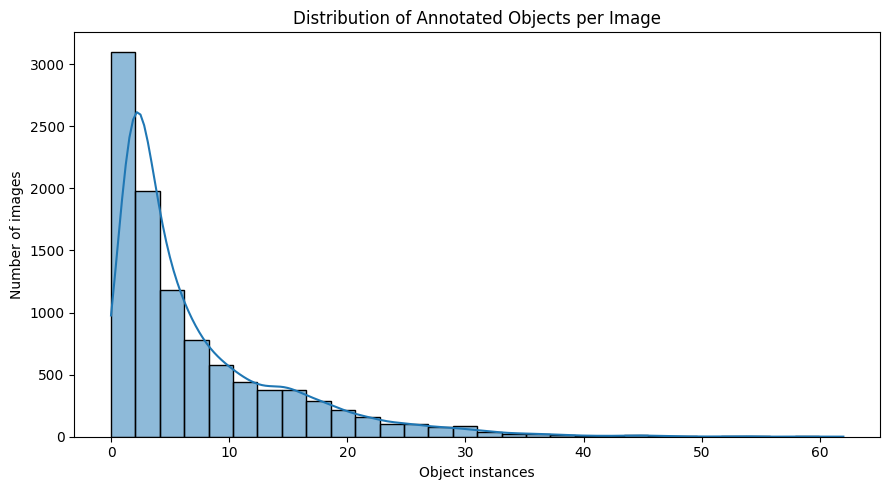

In [22]:
object_count_by_image = Counter(
    ann["image_id"] for ann in kb_objects
)

complexity_df = pd.DataFrame({
    "image_id": knowledge_base_ids,
    "object_count": [
        object_count_by_image.get(i, 0)
        for i in knowledge_base_ids
    ],
})

print(complexity_df["object_count"].describe())

plt.figure(figsize=(9, 5))
sns.histplot(
    complexity_df["object_count"],
    bins=30,
    kde=True,
)
plt.title("Distribution of Annotated Objects per Image")
plt.xlabel("Object instances")
plt.ylabel("Number of images")
plt.tight_layout()
plt.savefig(
    REPORTS_ROOT / "figures" / "scene_complexity.png",
    dpi=200,
)
plt.show()

In [23]:
from itertools import combinations
from collections import Counter

objects_per_image = {}

for ann in kb_objects:
    image_id = ann["image_id"]
    objects_per_image.setdefault(image_id, []).append(
        category_names[ann["category_id"]]
    )

cooccurrence = Counter()

for categories in objects_per_image.values():
    unique_categories = sorted(set(categories))
    for a, b in combinations(unique_categories, 2):
        cooccurrence[(a, b)] += 1

top_pairs = pd.DataFrame(
    [
        {"object_a": a, "object_b": b, "images": count}
        for (a, b), count in cooccurrence.most_common(30)
    ]
)

display(top_pairs.head(10))

,object_a,object_b,images
0,car,person,710
1,chair,person,666
2,handbag,person,517
3,dining table,person,495
4,chair,dining table,428
5,cup,person,423
6,backpack,person,394
7,bottle,person,372
8,cup,dining table,367
9,bench,person,349


This cell performs a co-occurrence analysis to find out which object categories are most frequently seen together in the same images within your Knowledge Base.

Here is how the code works step-by-step:

Group Objects by Image: It maps each image ID in the Knowledge Base to a list of all object names annotated in that image (objects_per_image).
Generate Unique Pairs: For each image, it extracts the unique categories present, sorts them, and uses itertools.combinations to find all unique pairs of objects appearing in that image (e.g., if an image contains car and person, it records the pair ('car', 'person')).
Count Co-occurrences: It keeps a running tally of these pairs using a Counter. If multiple instances of the same object appear (e.g., two cars), it only counts the pair association once per image.
Display Top Associations: It converts the 30 most common pairings into a Pandas DataFrame (top_pairs) and displays the top 10.
Key Insight from the Output: The results show strong contextual relationships:

car + person is the most common pair (appearing together in 710 images).
chair + person (666 images) and handbag + person (517 images) are also extremely frequent, reflecting common daily life scenes in the MS COCO dataset.

In [24]:
import re

def word_count(text):
    return len(re.findall(r"\b\w+(?:['’]\w+)?\b", text))

kb_captions["word_count"] = (
    kb_captions["caption_raw"].map(word_count)
)

all_words = [
    token
    for caption in kb_captions["caption_clean"]
    for token in caption.split()
]

print("Number of captions:", len(kb_captions))
print("Average caption length:",
      kb_captions["word_count"].mean())
print("Median caption length:",
      kb_captions["word_count"].median())
print("Vocabulary size:", len(set(all_words)))

Number of captions: 50030
Average caption length: 10.460523685788527
Median caption length: 10.0
Vocabulary size: 13892


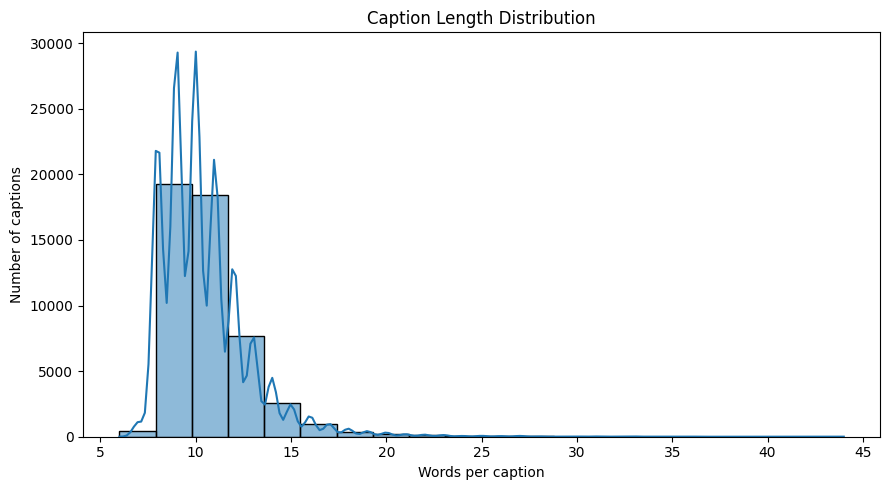

In [25]:
plt.figure(figsize=(9, 5))
sns.histplot(
    kb_captions["word_count"],
    bins=20,
    kde=True,
)
plt.title("Caption Length Distribution")
plt.xlabel("Words per caption")
plt.ylabel("Number of captions")
plt.tight_layout()
plt.savefig(
    REPORTS_ROOT / "figures" / "caption_lengths.png",
    dpi=200,
)
plt.show()

This cell performs a statistical text analysis of the raw and cleaned captions within your Knowledge Base to understand their length characteristics and overall vocabulary:

Word Counting:

It defines a helper function word_count that uses regular expressions to find all complete words (including those with contractions like it's or don't).
It calculates the word count for every raw caption in the Knowledge Base dataset and stores these metrics in a new column: kb_captions["word_count"].
Vocabulary Extraction:

It flattens all the words from the pre-cleaned captions (kb_captions["caption_clean"]) into a single list (all_words).
Key Descriptive Statistics Output:

Number of captions: 50,030 captions are processed.
Average caption length: The average caption contains ~10.46 words.
Median caption length: The middle value is exactly 10.0 words, indicating a highly balanced and consistent length distribution.
Vocabulary size: There are 13,892 unique words across all 50,030 captions, demonstrating a diverse lexicography suitable for RAG context retrieval.

In [26]:
import nltk

nltk.download("averaged_perceptron_tagger_eng")
nltk.download("punkt_tab")

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

,POS_tag,count
0,NN,154152
1,DT,107944
2,IN,83843
3,JJ,42913
4,.,37630
5,VBG,30817
6,NNS,30648
7,VBZ,13691
8,CC,11936
9,VBN,6823


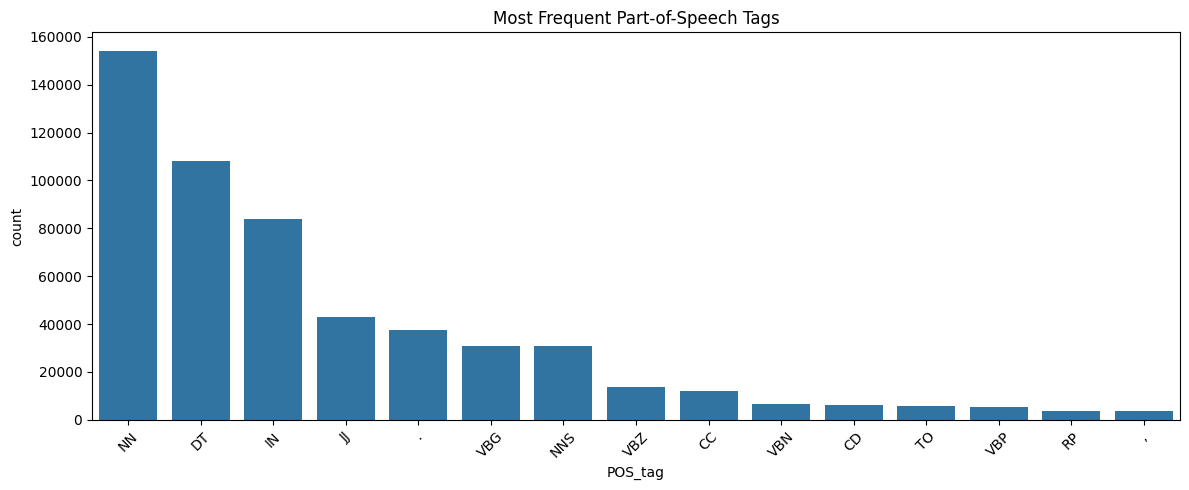

In [27]:
from nltk.tokenize import word_tokenize
from collections import Counter

pos_counts = Counter()

for caption in kb_captions["caption_clean"]:
    tokens = word_tokenize(caption)
    tagged = nltk.pos_tag(tokens)
    pos_counts.update(tag for _, tag in tagged)

pos_df = pd.DataFrame(
    pos_counts.most_common(),
    columns=["POS_tag", "count"],
)

display(pos_df.head(20))

plt.figure(figsize=(12, 5))
sns.barplot(
    data=pos_df.head(15),
    x="POS_tag",
    y="count",
)
plt.title("Most Frequent Part-of-Speech Tags")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    REPORTS_ROOT / "figures" / "pos_distribution.png",
    dpi=200,
)
plt.show()

This cell performs a Part-of-Speech (POS) tagging analysis on all the preprocessed captions within your Knowledge Base. This step is crucial for understanding the grammatical structure and syntactic style of the descriptions that will feed your RAG model.

Here is what the code achieves:

Tokenization & Tagging:

It tokenizes each clean caption into individual words using NLTK's word_tokenize tool.
It uses NLTK's pos_tag (using the downloaded Penn Treebank tagset models) to identify grammatical roles (e.g., nouns, verbs, determiners) for every word.
Frequency Count:

It counts the occurrences of each POS tag across the entire corpus using Counter and formats the results into a sorted DataFrame (pos_df).
Visualization:

It outputs a bar plot showing the top 15 most frequent POS tags.
The visualization is automatically saved to your Drive at reports/split_statistics/figures/pos_distribution.png.
Key Linguistic Insight from the Output:

NN (Singular Noun): By far the most common tag (154,152 occurrences), followed by DT (Determiner) (107,944) and IN (Preposition) (83,843).
This distribution mathematically demonstrates that image captions in MS COCO are highly descriptive noun-phrases (e.g., "A [DT] person [NN] on [IN] a [DT] surfboard [NN]"), with very high density on object nouns rather than complex action verbs.